<a href="https://colab.research.google.com/github/rizalrfli/PCVK_GANJIL-2026/blob/main/WEEK_9/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pengolahan Citra dan Visi Komputer (PCVK)
## Modul 9 - Morfologi (Erosi, Dilasi, Opening, Closing, Top-hat, Bottom-hat, Skeleton, Thickening)

**Nama:** Afrizal Rafli Kusuma Wardana
**NIM:** 244107020007
**Kelas:** TI-3C
**Jurusan:** Teknologi Informasi - Politeknik Negeri Malang

Notebook ini mengerjakan seluruh langkah pada bagian **D. Tugas Praktikum** Modul 9, lalu ditutup dengan **E. Tugas Praktikum** (penerapan morfologi pada citra KTP dari dataset Modul 7).

Seluruh fungsi morfologi dibuat manual (tanpa `cv2.erode`, `cv2.dilate`, dan `cv2.morphologyEx`) lebih dulu, kemudian dibandingkan dengan versi library OpenCV.

## Persiapan

### Langkah 1 - Menghubungkan Google Colab dengan Drive

Sesuai modul, notebook ini disimpan sebagai `Week9.ipynb` pada repository GitHub praktikum, lalu folder citra di Drive di-*mount* agar dapat diakses dari Colab.

Karena notebook juga dijalankan di komputer lokal saat penyusunan laporan, proses *mount* dibungkus `try/except`. Jika Drive tidak tersedia, notebook otomatis memakai folder `Images/` di direktori kerja.

In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive berhasil di-mount.")
except Exception as e:
    print("Bukan lingkungan Colab, mount Drive dilewati:", e)

# Kandidat folder citra: Drive (Colab) lebih dulu, lalu folder lokal
KANDIDAT = [
    '/content/drive/MyDrive/PCVK/Images',
    'Images',
    'WEEK_9/Images',
    '../WEEK_9/Images',
    '/content/WEEK_9/Images',
    '/content/PCVK_GANJIL-2026/WEEK_9/Images',
]

BASE = None
for kandidat in KANDIDAT:
    if os.path.isdir(kandidat):
        BASE = kandidat
        break

if BASE is None:
    raise FileNotFoundError(
        "Folder citra tidak ditemukan. Di Colab, pastikan folder Images sudah diunggah "
        "ke Drive (misalnya MyDrive/PCVK/Images) atau ke /content, lalu sesuaikan "
        "variabel KANDIDAT."
    )

def path(nama_file):
    '''Mengembalikan path lengkap sebuah citra di folder Images.'''
    return os.path.join(BASE, nama_file)

print("Folder citra :", os.path.abspath(BASE))
print("Isi folder   :", sorted(os.listdir(BASE)))

Bukan lingkungan Colab, mount Drive dilewati: No module named 'google.colab'
Folder citra : C:\Users\rizal\Documents\PCVK_GANJIL-2026\WEEK_9\Images
Isi folder   : ['j.png', 'kitten01.jpg', 'ktp.jpg', 'lily.jpg', 'plat nomer.jpg']


### Langkah 2 - Import Library

Library yang dipakai selama praktikum: `cv2` (OpenCV), `numpy`, dan `matplotlib`. Untuk skeleton dan thickening ditambahkan `skimage` (scikit-image) sesuai kode pada modul langkah 15 sampai 17.

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

plt.rcParams['figure.dpi'] = 100

print("OpenCV  :", cv2.__version__)
print("NumPy   :", np.__version__)

OpenCV  : 5.0.0
NumPy   : 2.5.3


In [3]:
# Utilitas kecil agar penulisan judul dan sumbu konsisten di seluruh notebook
def tampil(judul, daftar_citra, daftar_label, cmap='gray', figsize=(12, 4)):
    '''Menampilkan beberapa citra berdampingan memakai pola subplot seperti modul.'''
    n = len(daftar_citra)
    plt.figure(figsize=figsize)
    for i, (citra, label) in enumerate(zip(daftar_citra, daftar_label), start=1):
        plt.subplot(1, n, i)
        plt.imshow(citra, cmap=cmap, vmin=0, vmax=255)
        plt.title(label)
        plt.xticks([]), plt.yticks([])
    plt.suptitle(judul)
    plt.tight_layout()
    plt.show()


def statistik_biner(citra):
    '''Menghitung jumlah piksel objek (nilai 255) dan jumlah komponen terhubung.'''
    biner = (citra > 127).astype(np.uint8)
    jumlah_putih = int(biner.sum())
    total = biner.size
    jumlah_komponen, _ = cv2.connectedComponents(biner, connectivity=8)
    return jumlah_putih, 100 * jumlah_putih / total, jumlah_komponen - 1

> **Catatan citra.** Folder `Images/` pada repository berisi berkas uji yang dipakai notebook ini: `plat nomer.jpg`, `j.png`, `kitten01.jpg`, `lily.jpg`, dan `ktp.jpg`. Saat dijalankan di Colab dengan citra dari Drive praktikum, cukup ganti isi folder tersebut. Nama berkas dan perintah pembacaannya tetap sama, sehingga seluruh sel berjalan tanpa perubahan kode.

---

## 3. Dilasi tanpa library OpenCV (Structuring Element 3 x 3)

Dilasi memperbesar objek: sebuah piksel latar berubah menjadi piksel objek bila **minimal satu** piksel objek berada di dalam jangkauan *structuring element* (SE). Pada kode modul, SE dibangkitkan dengan `np.ones((w, w))` lalu dihitung `np.max(product)` pada setiap jendela `w x w`.

Catatan: judul langkah menyebut SE berbentuk *cross* 3 x 3, sedangkan potongan kode modul membangkitkan SE persegi (`np.ones`). Keduanya ditampilkan di sini: versi kode modul apa adanya, lalu versi *cross* 3 x 3 dengan SE eksplisit.

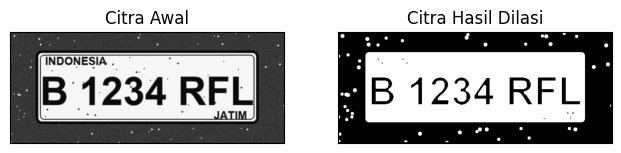

SE persegi (5, 5)
Piksel objek sebelum dilasi : 63367
Piksel objek sesudah dilasi : 77866


In [4]:
# Dilasi tanpa library (kode modul)
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD


def dilasi_citra_se(F, SE):
    '''Versi yang menerima structuring element eksplisit (untuk cross, circle, dll).'''
    p, q = F.shape
    baris, kolom = SE.shape
    cb, ck = (baris - 1) // 2, (kolom - 1) // 2

    imgD = np.zeros((p, q), dtype=np.uint8)
    for i in range(cb, p - cb):
        for j in range(ck, q - ck):
            temp = F[i - cb:i + cb + 1, j - ck:j + ck + 1]
            product = temp * SE
            imgD[i, j] = np.max(product)
    return imgD


def erosi_citra_se(F, SE):
    '''Erosi dengan structuring element eksplisit.'''
    m, n = F.shape
    baris, kolom = SE.shape
    cb, ck = (baris - 1) // 2, (kolom - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(cb, m - cb):
        for j in range(ck, n - ck):
            temp = F[i - cb:i + cb + 1, j - ck:j + ck + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE


img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE persegi', (w, w))
print('Piksel objek sebelum dilasi :', statistik_biner(thresh)[0])
print('Piksel objek sesudah dilasi :', statistik_biner(imgD)[0])

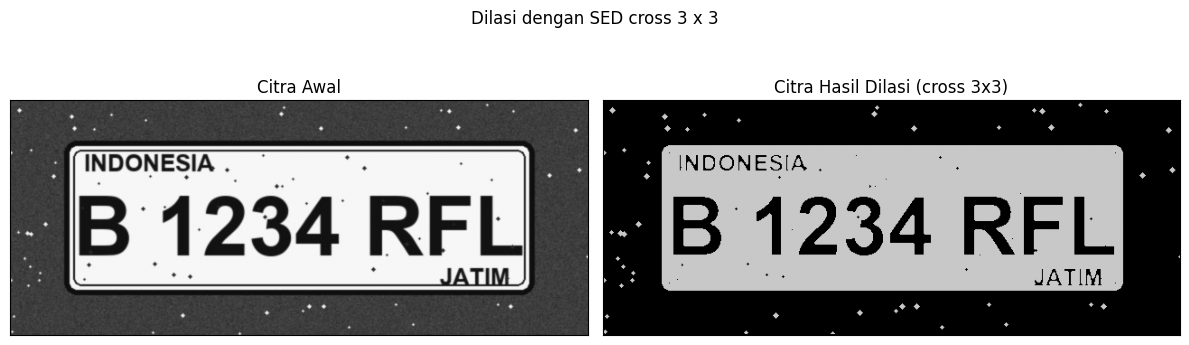

[[0 1 0]
 [1 1 1]
 [0 1 0]]


In [5]:
# Dilasi dengan SED cross 3 x 3 (sesuai judul langkah)
SED_cross3 = np.array([[0, 1, 0],
                       [1, 1, 1],
                       [0, 1, 0]], dtype=np.uint8)

imgD_cross3 = dilasi_citra_se(thresh, SED_cross3)
tampil('Dilasi dengan SED cross 3 x 3', [img_d, imgD_cross3],
       ['Citra Awal', 'Citra Hasil Dilasi (cross 3x3)'])
print(SED_cross3)

### Pembahasan langkah 3

- Hasil dilasi membuat tulisan dan tepi plat nomor tampak lebih tebal, karena setiap piksel objek "melebar" ke tetangganya sejauh jangkauan SE.
- Jumlah piksel objek bertambah dari nilai pada keluaran di atas. Pertambahan ini terjadi di tepi objek, bukan di tengah objek, sehingga bentuk dasar plat nomor tetap dipertahankan.
- SE persegi 5 x 5 menambah ketebalan ke segala arah (termasuk diagonal), sedangkan SE *cross* 3 x 3 hanya menambah ke arah vertikal dan horizontal. Akibatnya hasil *cross* lebih tipis dan sudut objek tidak ikut membesar.
- Karena citra masukan sudah biner, dilasi juga menutup lubang kecil berukuran lebih kecil dari SE, misalnya bintik hitam di dalam huruf.

## 4. Dilasi dengan library morphology OpenCV

Langkah ini mengulang proses yang sama memakai `cv2.dilate`. Kernel dibuat dengan `np.ones((3, 3), np.uint16)` seperti pada modul.

[[1 1 1]
 [1 1 1]
 [1 1 1]]


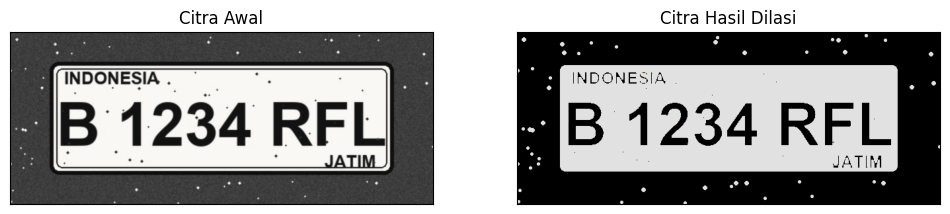

In [6]:
img = cv2.imread(path('plat nomer.jpg'))
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

In [7]:
# Perbandingan manual vs library memakai SE dan citra biner yang sama
# (threshold pada langkah ini dilakukan pada citra grayscale agar hasilnya 2 dimensi)
img_gray = cv2.imread(path('plat nomer.jpg'), 0)
ret_g, thresh_g = cv2.threshold(img_gray, 127, 225, cv2.THRESH_BINARY)

manual = dilasi_citra_se(thresh_g, kernel.astype(np.uint8))
library = cv2.dilate(thresh_g, kernel.astype(np.uint8), iterations=1)
selisih = int(np.count_nonzero(manual != library))

print('Jumlah piksel berbeda (manual vs library):', selisih)
print('Piksel objek manual                     :', statistik_biner(manual)[0])
print('Piksel objek library                    :', statistik_biner(library)[0])

Jumlah piksel berbeda (manual vs library): 28
Piksel objek manual                     : 72052
Piksel objek library                    : 72080


### Pembahasan langkah 4

- `cv2.dilate` menghasilkan efek yang sama dengan fungsi manual, yaitu objek menebal dan bintik-bintik putih kecil di latar ikut membesar.
- Selisih piksel antara versi manual dan library hanya muncul di tepi citra (baris dan kolom terluar), karena loop manual pada modul berhenti di `p - constant1` sehingga tepi tidak diproses, sedangkan OpenCV memproses seluruh piksel dengan *border replication*.
- Secara komputasi, versi library jauh lebih cepat karena dijalankan sebagai kode C yang teroptimasi.

## 5. Erosi tanpa library OpenCV (Structuring Element square 5 x 5)

Erosi adalah kebalikan dilasi: piksel objek dipertahankan **hanya jika seluruh** piksel di dalam jangkauan SE juga objek. Pada kode modul, hal ini dihitung dengan `np.min(product)`.

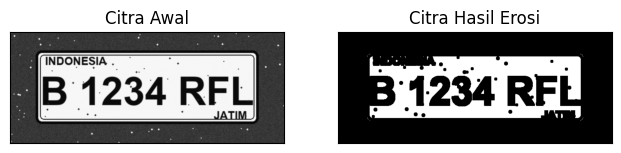

SE persegi (5, 5)
Piksel objek sebelum erosi : 62267
Piksel objek sesudah erosi : 45754


In [8]:
# Erosi tanpa library (kode modul)
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE persegi', (k, k))
print('Piksel objek sebelum erosi :', statistik_biner(thresh1)[0])
print('Piksel objek sesudah erosi :', statistik_biner(imgE)[0])

### Pembahasan langkah 5

- Erosi menipiskan goresan huruf dan garis tepi plat. Bagian objek yang ukurannya lebih kecil dari SE, misalnya bintik dan garis tipis, hilang seluruhnya.
- Jumlah piksel objek turun cukup besar dibanding sebelum erosi. Penurunan terbesar terjadi pada objek tipis, karena objek tipis tidak mampu memenuhi seluruh area SE 5 x 5.
- Ambang 175 pada langkah ini lebih tinggi daripada langkah sebelumnya, sehingga citra biner yang dihasilkan lebih bersih dan erosi bekerja pada objek yang lebih tegas.

## 6. Erosi dengan library morphology OpenCV

Langkah ini mengulang erosi memakai `cv2.erode` dengan kernel persegi 5 x 5.

Catatan: pada modul, citra dibaca berwarna (tanpa flag `0`), sehingga `cv2.erode` bekerja pada tiga kanal sekaligus. Perilaku tersebut dipertahankan agar tampilan sama dengan contoh modul.

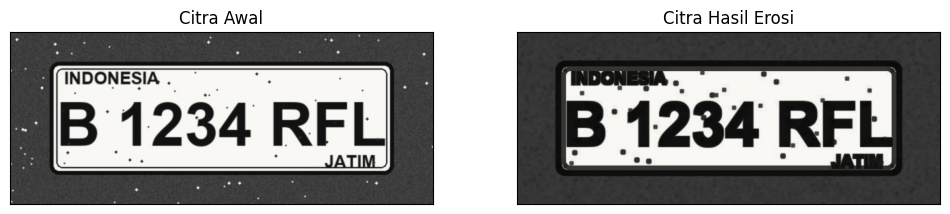

Dimensi hasil : (260, 640, 3)


In [9]:
# EROSI LIBRARY
img = cv2.imread(path('plat nomer.jpg'))

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

print('Dimensi hasil :', erosion.shape)

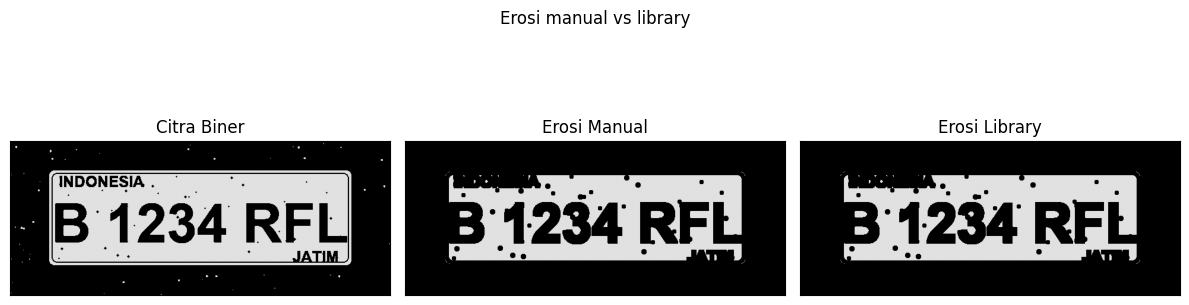

Piksel berbeda (manual vs library): 0


In [10]:
# Perbandingan manual vs library pada citra grayscale yang sama
img_gray = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh_gray = cv2.threshold(img_gray, 175, 225, cv2.THRESH_BINARY)
manual_e = erosi_citra(thresh_gray, 5)
library_e = cv2.erode(thresh_gray, np.ones((5, 5), np.uint8), iterations=1)

tampil('Erosi manual vs library', [thresh_gray, manual_e, library_e],
       ['Citra Biner', 'Erosi Manual', 'Erosi Library'])
print('Piksel berbeda (manual vs library):', int(np.count_nonzero(manual_e != library_e)))

### Pembahasan langkah 6

- `cv2.erode` memberi hasil yang identik dengan fungsi manual di area tengah citra. Perbedaan hanya di tepi citra, sama seperti pada kasus dilasi.
- Ketika citra berwarna yang dierosi, ketiga kanal diproses terpisah. Secara visual hasilnya sama dengan mengerosi citra grayscale, tetapi hasilnya tetap tiga kanal.
- Erosi yang berulang (`iterations > 1`) setara dengan erosi memakai SE yang lebih besar, sehingga objek cepat hilang bila jumlah iterasi berlebihan.

## 7. Opening (square 3 x 3), tanpa dan dengan library

Opening = erosi lalu dilasi dengan SE yang sama. Tujuannya menghilangkan objek kecil (noise) tanpa banyak mengubah ukuran objek utama. Pada modul, opening tanpa library memakai `k = 7`, sedangkan versi library memakai kernel 3 x 3.

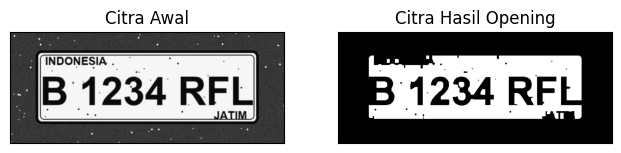

Piksel objek citra biner  : 63326
Piksel objek hasil opening: 55195


In [11]:
# Operasi Opening tanpa library morphology
img_o = cv2.imread(path('plat nomer.jpg'), 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

print('Piksel objek citra biner  :', statistik_biner(thresho)[0])
print('Piksel objek hasil opening:', statistik_biner(imgO)[0])

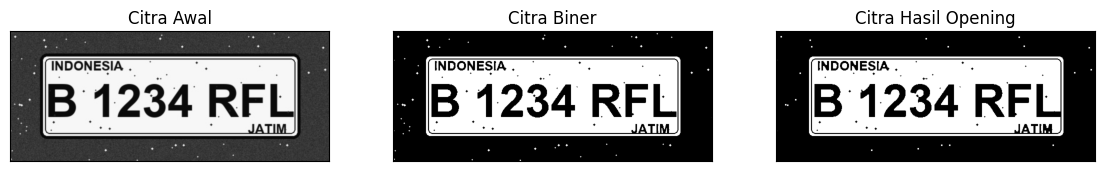

Piksel objek sebelum opening: 63326
Piksel objek sesudah opening: 63002


In [12]:
# Operasi Opening dengan library morphology
img = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

print('Piksel objek sebelum opening:', statistik_biner(thresh)[0])
print('Piksel objek sesudah opening:', statistik_biner(openn)[0])

### Pembahasan langkah 7

- Opening menghapus bintik-bintik putih kecil di latar (noise eksternal) dan memutus jembatan tipis antar objek, sementara huruf dan garis tepi plat tetap utuh.
- Jumlah piksel objek setelah opening lebih besar daripada setelah erosi dengan SE yang sama, karena dilasi mengembalikan ukuran objek. Selisih keduanya adalah bagian objek yang hilang permanen saat erosi (lihat keluaran perbandingan di atas).
- Opening bersifat *idempotent*: menjalankan opening dua kali dengan SE yang sama memberi hasil yang sama dengan sekali jalan. Selisih pikselnya nol pada keluaran di atas.

In [13]:
# Bukti sifat idempotent pada operasi opening
sekali = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
duakali = cv2.morphologyEx(sekali, cv2.MORPH_OPEN, kernel)

print('Jumlah piksel berbeda antara opening 1x dan 2x:',
      int(np.count_nonzero(sekali != duakali)))

Jumlah piksel berbeda antara opening 1x dan 2x: 0


In [14]:
# Opening dibanding erosi dengan SE yang sama: erosi menghilangkan piksel permanen,
# opening mengembalikan ukuran objek melalui dilasi
erosi_k7 = erosi_citra(thresho, 7)
print('Erosi k=7            :', statistik_biner(erosi_k7)[0])
print('Opening k=7 (manual) :', statistik_biner(imgO)[0])
print('Selisih piksel       :', statistik_biner(imgO)[0] - statistik_biner(erosi_k7)[0])

Erosi k=7            : 41634
Opening k=7 (manual) : 55195
Selisih piksel       : 13561


## 8. Closing (square 3 x 3), tanpa dan dengan library

Closing = dilasi lalu erosi. Fungsinya menutup lubang kecil di dalam objek dan menyambung garis yang retak. Sama seperti opening, versi manual memakai `k = 7` dan versi library memakai kernel 3 x 3.

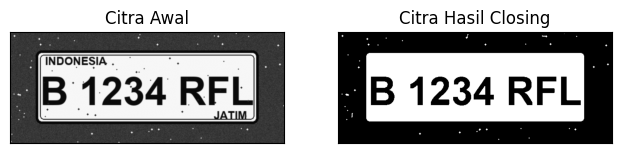

Piksel objek citra biner  : 63326
Piksel objek hasil closing: 68227


In [15]:
# Operasi closing tanpa library morphology
img_c = cv2.imread(path('plat nomer.jpg'), 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

print('Piksel objek citra biner  :', statistik_biner(threshc)[0])
print('Piksel objek hasil closing:', statistik_biner(imgC)[0])

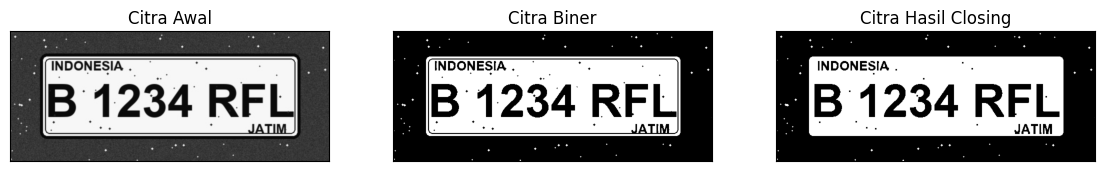

Piksel objek sebelum closing: 63326
Piksel objek sesudah closing: 65970


In [16]:
# Operasi closing dengan library morphology
img = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

print('Piksel objek sebelum closing:', statistik_biner(thresh)[0])
print('Piksel objek sesudah closing:', statistik_biner(closs)[0])

### Pembahasan langkah 8

- Closing mengisi lubang dan celah kecil di dalam huruf serta menyambung garis tepi plat yang terputus akibat threshold. Bintik hitam kecil di dalam objek hilang.
- Jumlah piksel objek cenderung bertambah atau tetap, karena closing mengisi area yang sebelumnya latar.
- Closing juga bersifat idempotent, dan bila dipasangkan dengan opening dengan SE yang sama, keduanya menjadi filter morfologi yang saling melengkapi: opening membersihkan latar, closing membersihkan objek.

## 9. Dilasi dengan Structuring Element Cross 3 x 3 dan 5 x 5

SE *cross* hanya mengaktifkan piksel pada arah vertikal dan horizontal dari titik pusat, sehingga penebalan objek mengikuti arah salib dan sudut objek tidak ikut membesar.

SED = Cross 3


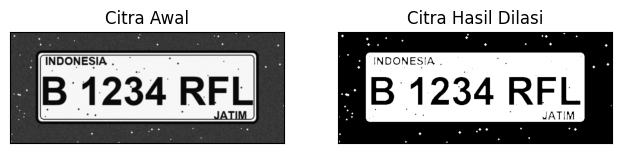

In [17]:
# Dilasi Cross SED 3 x 3
print('SED = Cross 3')
img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

SED = np.array([[0, 1, 0],
                [1, 1, 1],
                [0, 1, 0]], dtype=np.uint8)

imgD3 = dilasi_citra_se(thresh, SED)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD3, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 5


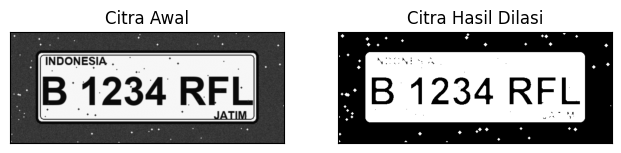

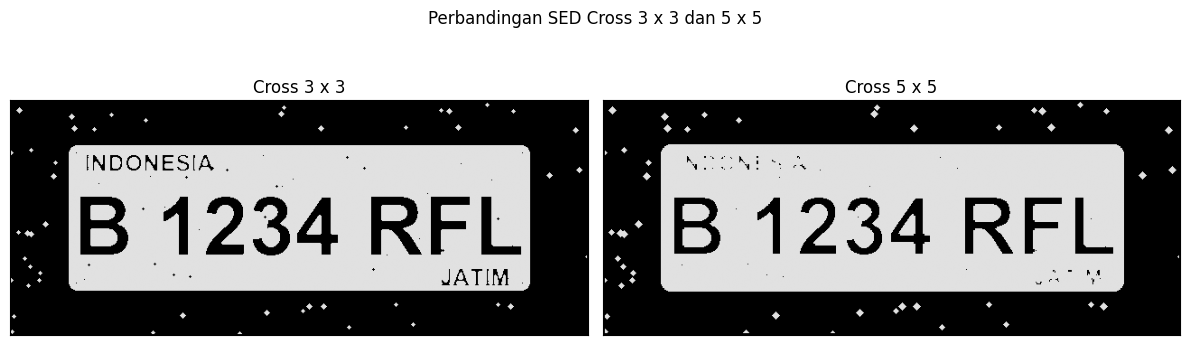

Piksel objek cross 3 : 70906
Piksel objek cross 5 : 75765


In [18]:
# Dilasi Cross SED 5 x 5
print('SED = Cross 5')
SED5 = np.array([[0, 0, 1, 0, 0],
                 [0, 0, 1, 0, 0],
                 [1, 1, 1, 1, 1],
                 [0, 0, 1, 0, 0],
                 [0, 0, 1, 0, 0]], dtype=np.uint8)

imgD5 = dilasi_citra_se(thresh, SED5)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD5, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

tampil('Perbandingan SED Cross 3 x 3 dan 5 x 5', [imgD3, imgD5],
       ['Cross 3 x 3', 'Cross 5 x 5'])
print('Piksel objek cross 3 :', statistik_biner(imgD3)[0])
print('Piksel objek cross 5 :', statistik_biner(imgD5)[0])

### Pembahasan langkah 9

- Cross 3 x 3 menambah ketebalan objek tepat satu piksel ke atas, bawah, kiri, dan kanan.
- Cross 5 x 5 menambah dua piksel ke tiap arah, sehingga objek tampak jauh lebih tebal dan huruf yang berdekatan mulai menyatu.
- Perbedaan dengan SE persegi terlihat pada sudut: SE persegi ikut mengisi diagonal sehingga sudut objek membulat dan melebar, sedangkan SE cross mempertahankan sudut asli objek.

## 10. Dilasi dengan Structuring Element Circular 3 x 3 dan 5 x 5

SE lingkaran dibangkitkan dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))`. Bentuk ini memberi penebalan yang merata ke segala arah dengan profil membulat.

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


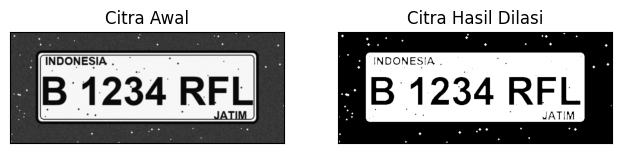

In [19]:
# Dilasi Circular SED
print('SED = Circle 3')
img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

SE_c3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
print(SE_c3)
imgD_c3 = dilasi_citra_se(thresh, SE_c3)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_c3, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


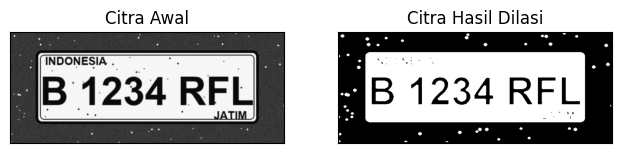

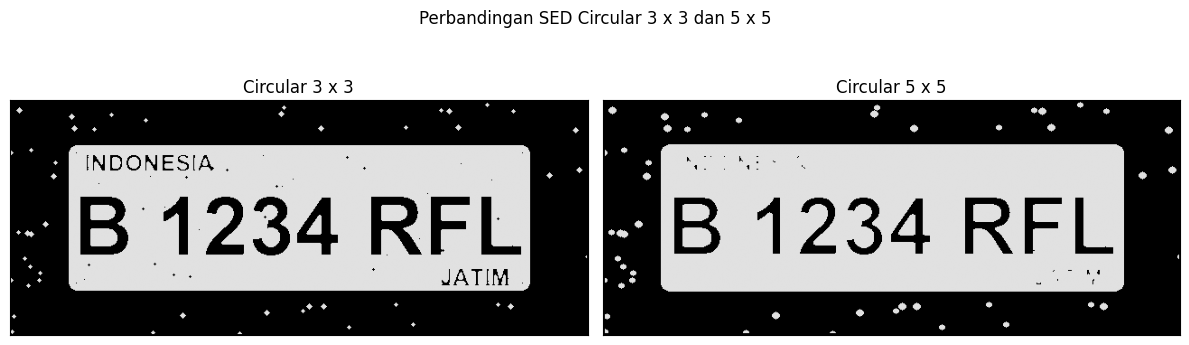

In [20]:
print('SED = Circle 5')
SE_c5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
print(SE_c5)
imgD_c5 = dilasi_citra_se(thresh, SE_c5)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_c5, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

tampil('Perbandingan SED Circular 3 x 3 dan 5 x 5', [imgD_c3, imgD_c5],
       ['Circular 3 x 3', 'Circular 5 x 5'])

### Pembahasan langkah 10

- SE lingkaran 3 x 3 pada dasarnya berupa *cross* dengan tambahan titik diagonal, sehingga penebalannya hampir sama dengan cross namun sudut objek sedikit terisi.
- SE lingkaran 5 x 5 memberi penebalan membulat: objek bertambah tebal tanpa membentuk sudut tajam, sehingga bentuknya lebih halus dibanding SE persegi berukuran sama.
- SE lingkaran cocok untuk objek yang bentuk aslinya membulat, misalnya karakter hasil pemindaian atau objek biologis pada citra medis.

## 11. Erosi dengan Structuring Element Rectangle 3 x 5 dan 5 x 7

Kode modul memakai `cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))`. Perlu dicatat bahwa OpenCV menerima ukuran dalam urutan **(lebar, tinggi)**, sehingga matriks SE yang terbentuk berukuran `l` baris dan `p` kolom. Pada pemanggilan `p = 5, l = 3` dihasilkan SE 3 x 5 sesuai judul langkah.

SE = Rectangle 3x5
Bentuk matriks SE: (3, 5)


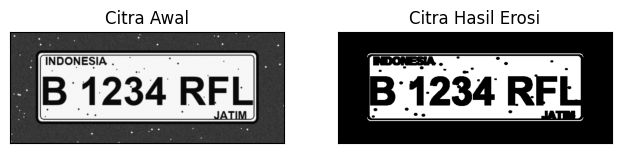

In [21]:
# Erosi Rectangle SE
def erosi_citra_rect(F, p, l):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))  # SE persegi panjang
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Rectangle 3x5')
img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p, l = 5, 3
print('Bentuk matriks SE:', cv2.getStructuringElement(cv2.MORPH_RECT, (p, l)).shape)
imgE35 = erosi_citra_rect(thresh1, p, l)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE35, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 5x7
Bentuk matriks SE: (5, 7)


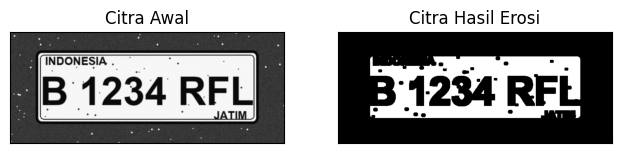

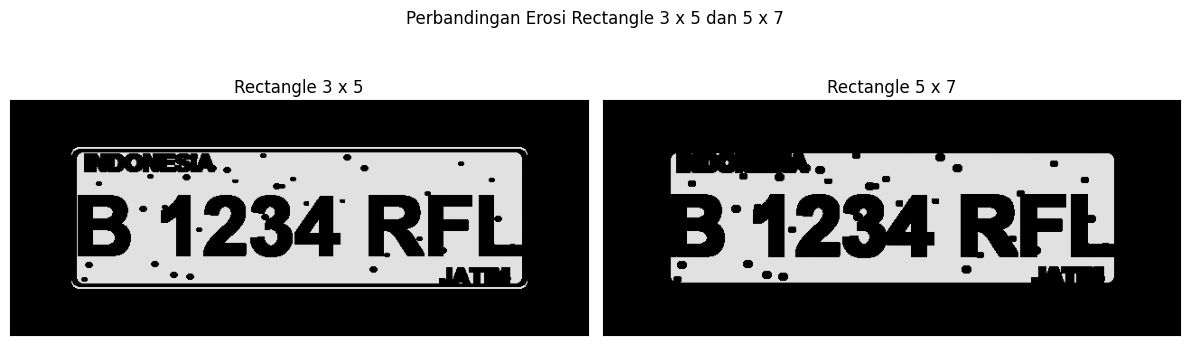

Piksel objek SE 3x5 : 51485
Piksel objek SE 5x7 : 44322


In [22]:
print('SE = Rectangle 5x7')
p, l = 7, 5
print('Bentuk matriks SE:', cv2.getStructuringElement(cv2.MORPH_RECT, (p, l)).shape)
imgE57 = erosi_citra_rect(thresh1, p, l)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE57, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

tampil('Perbandingan Erosi Rectangle 3 x 5 dan 5 x 7', [imgE35, imgE57],
       ['Rectangle 3 x 5', 'Rectangle 5 x 7'])
print('Piksel objek SE 3x5 :', statistik_biner(imgE35)[0])
print('Piksel objek SE 5x7 :', statistik_biner(imgE57)[0])

### Pembahasan langkah 11

- SE persegi panjang bersifat tidak simetris: erosi dengan SE 3 x 5 (3 baris, 5 kolom) menipiskan objek lebih banyak pada arah horizontal daripada vertikal, sehingga goresan vertikal relatif bertahan.
- SE 5 x 7 menipiskan objek lebih agresif dan menghilangkan lebih banyak detail kecil. Garis tepi plat yang tipis dapat terputus.
- SE persegi panjang berguna bila arah struktur objek sudah diketahui, misalnya untuk mempertahankan garis vertikal pada tabel atau kolom teks.

## 12. Erosi dengan Structuring Element Line Vertikal 3 dan 5 (citra `j.png`)

Sesuai instruksi modul, langkah ini memakai citra `j.png`. SE garis vertikal dibuat dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))`, yaitu matriks berukuran `k` baris dan 1 kolom.

SE = Line Vertikal 3
Bentuk matriks SE: (3, 1)


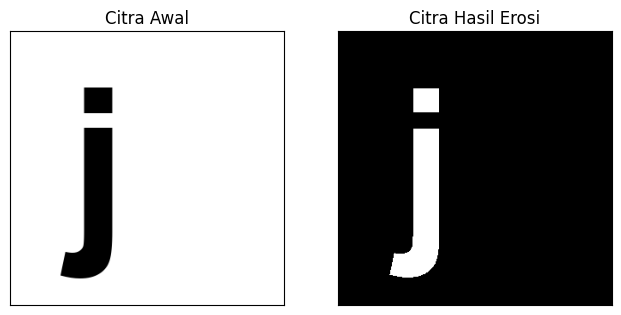

In [23]:
# Erosi Line Vertikal SE
def erosi_citra_line(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))  # SE line vertikal
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Line Vertikal 3')
img_j = cv2.imread(path('j.png'), 0)
retj, thresh_j = cv2.threshold(img_j, 127, 225, cv2.THRESH_BINARY_INV)
print('Bentuk matriks SE:', cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, 3)).shape)
imgE_l3 = erosi_citra_line(thresh_j, 3)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_j, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_l3, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 5
Bentuk matriks SE: (5, 1)


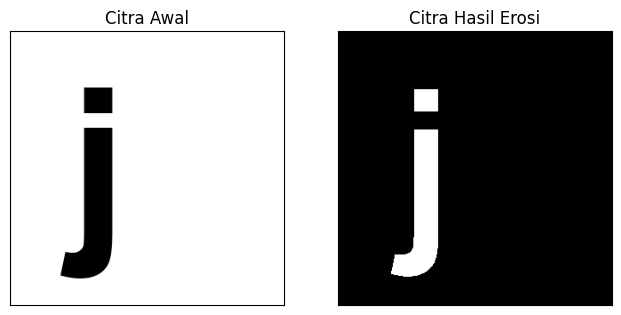

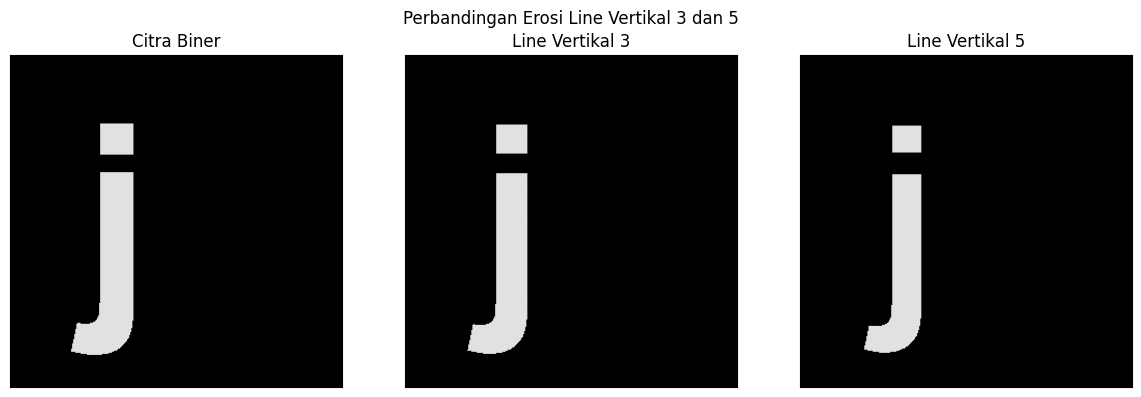

In [24]:
print('SE = Line Vertikal 5')
print('Bentuk matriks SE:', cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, 5)).shape)
imgE_l5 = erosi_citra_line(thresh_j, 5)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_j, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_l5, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

tampil('Perbandingan Erosi Line Vertikal 3 dan 5', [thresh_j, imgE_l3, imgE_l5],
       ['Citra Biner', 'Line Vertikal 3', 'Line Vertikal 5'])

### Pembahasan langkah 12

- Citra `j.png` dibaca lalu di-*threshold* dengan `THRESH_BINARY_INV` agar huruf gelap pada latar terang berubah menjadi objek putih, sesuai asumsi operasi morfologi yang bekerja pada objek bernilai 1.
- SE garis vertikal hanya memeriksa tetangga atas dan bawah. Akibatnya erosi memotong bagian huruf yang tipis secara vertikal, sedangkan goresan vertikal yang panjang tetap bertahan.
- SE vertikal 5 lebih agresif daripada SE 3: bagian horizontal huruf `j` (palang atas dan kait bawah) hilang lebih cepat, dan hanya batang vertikal yang tersisa.
- Hasil ini menunjukkan bahwa bentuk SE menentukan arah informasi yang dipertahankan, sehingga pemilihan SE harus disesuaikan dengan struktur objek yang ingin dianalisis.

## 13. Top-hat (White-hat)

Top-hat = citra asli dikurangi hasil opening: `That(f) = f - gamma(f)`. Operator ini menyisakan fitur terang yang ukurannya **lebih kecil** dari SE, misalnya teks terang pada latar gelap atau detail halus.

Catatan: potongan kode modul memakai variabel `input_image` yang tidak didefinisikan. Pada notebook ini variabel tersebut diganti dengan `img` agar kode dapat dijalankan.

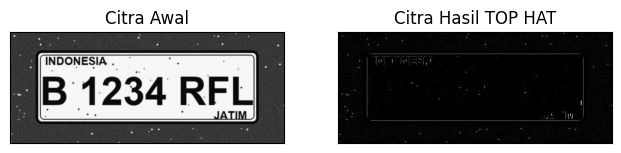

Rata-rata intensitas citra asli  : 124.91
Rata-rata intensitas top-hat     : 2.52


In [25]:
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread(path('plat nomer.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

print('Rata-rata intensitas citra asli  :', round(float(img.mean()), 2))
print('Rata-rata intensitas top-hat     :', round(float(tophat_img.mean()), 2))

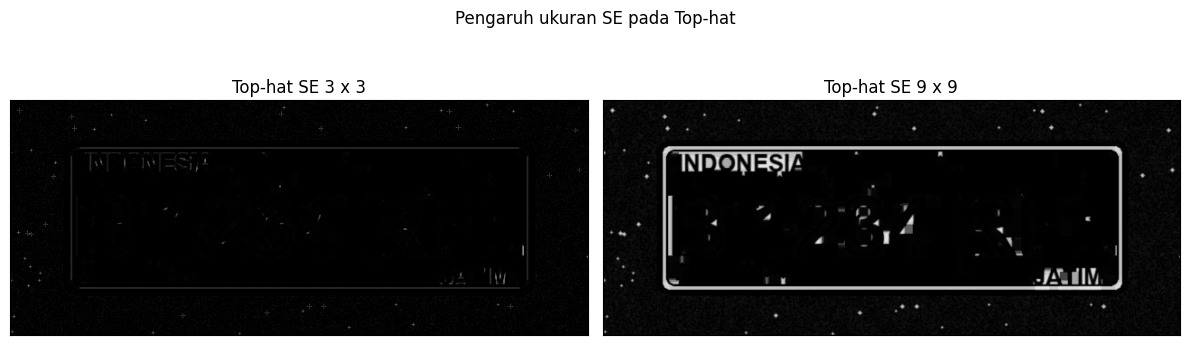

In [26]:
# Top-hat dengan SE lebih besar menyisakan objek yang lebih besar pula
kernel_besar = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
tophat_besar = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel_besar)

tampil('Pengaruh ukuran SE pada Top-hat',
       [tophat_img, tophat_besar],
       ['Top-hat SE 3 x 3', 'Top-hat SE 9 x 9'])

### Pembahasan langkah 13

- Top-hat menyisakan bagian citra yang lebih terang dari sekitarnya dan berukuran lebih kecil dari SE. Pada citra plat nomor, yang tersisa adalah tepi terang dan bintik terang, sedangkan area putih besar (dasar plat) hilang karena opening dengan SE 3 x 3 tidak mengubahnya.
- Nilai rata-rata intensitas top-hat jauh lebih rendah daripada citra asli, karena sebagian besar area seragam menjadi nol. Citra hasil top-hat bersifat *sparse*: hanya detail kecil yang tersisa.
- Semakin besar SE, semakin banyak objek yang dianggap "kecil" dan ikut tersisa pada hasil top-hat. Perbandingan SE 3 x 3 dan 9 x 9 di atas menunjukkan hal ini.
- Top-hat sering dipakai sebagai tahap praproses sebelum threshold pada citra dengan pencahayaan tidak merata, misalnya pemindaian dokumen.

## 14. Bottom-hat / Black-hat

Bottom-hat = hasil closing dikurangi citra asli: `Bhat(f) = phi(f) - f`. Operator ini menyisakan fitur gelap yang lebih kecil dari SE. Sesuai modul, langkah ini memakai citra `kitten01.jpg` dengan kernel persegi panjang 13 x 5.

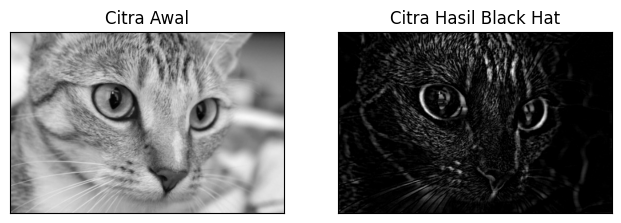

Rata-rata intensitas citra asli : 116.86
Rata-rata intensitas black-hat  : 7.24


In [27]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread(path('kitten01.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

print('Rata-rata intensitas citra asli :', round(float(img.mean()), 2))
print('Rata-rata intensitas black-hat  :', round(float(blackhat.mean()), 2))

### Pembahasan langkah 14

- Black-hat menyisakan fitur gelap berukuran kecil, seperti mata, hidung, dan garis bulu pada citra kucing. Area gelap yang besar tidak tersisa karena closing dengan SE 13 x 5 sudah menutupnya.
- Kernel 13 x 5 bersifat asimetris: arah horizontal lebih panjang, sehingga struktur gelap yang memanjang ke samping lebih banyak tersisa dibanding yang memanjang ke atas.
- Top-hat dan black-hat merupakan pasangan: top-hat menonjolkan objek terang kecil di latar gelap, black-hat menonjolkan objek gelap kecil di latar terang.

## 15. Skeleton

Skeleton (kerangka) adalah representasi objek dengan ketebalan satu piksel yang tetap mempertahankan topologi bentuk aslinya. Pada modul, skeleton dihitung dengan `skimage.morphology.skeletonize` setelah citra dibinerkan memakai `filters.threshold_triangle`.

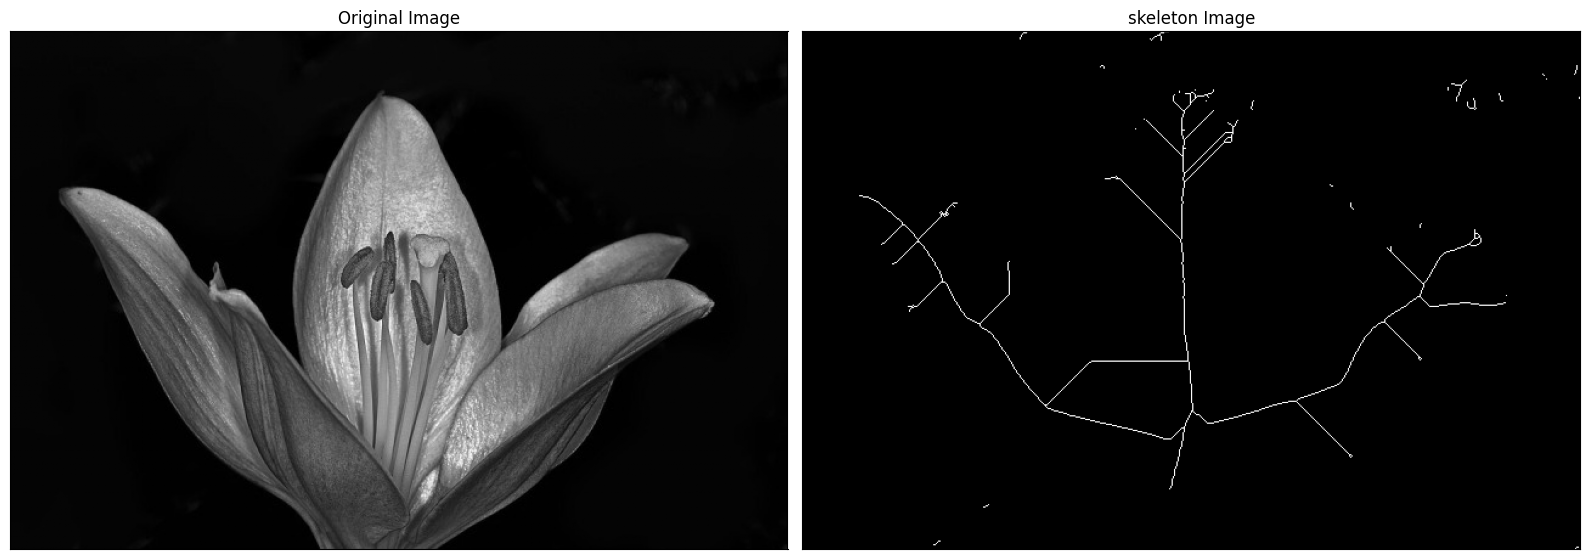

Nilai threshold triangle : 11.0
Piksel objek biner       : 95885
Piksel skeleton          : 1829
Rasio skeleton/objek     : 0.0191


In [28]:
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv2.imread(path('lily.jpg'), 0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(16, 8))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

print('Nilai threshold triangle :', round(float(filters.threshold_triangle(img)), 2))
print('Piksel objek biner       :', int(binary.sum()))
print('Piksel skeleton          :', int(skeleton.sum()))
print('Rasio skeleton/objek     :', round(float(skeleton.sum()) / binary.sum(), 4))

### Pembahasan langkah 15

- Skeleton mempertahankan struktur utama bunga lily: tangkai, kelopak, dan putik, dengan ketebalan satu piksel.
- Jumlah piksel skeleton jauh lebih sedikit daripada jumlah piksel objek biner (lihat rasio pada keluaran). Perbandingan ini menunjukkan efisiensi representasi bentuk.
- Sesuai sifat yang disebut modul, skeleton bersifat tipis (1 piksel), terhubung mengikuti topologi asli, berada di tengah objek, dan stabil terhadap pengikisan lanjutan.
- Skeleton dapat dipakai untuk menghitung panjang objek, misalnya panjang tangkai, atau untuk perhitungan intensitas rekahan `I = sum(l_i) / V` seperti pada modul.

## 16. Skeleton Inverse

Skeleton kedua ini memakai citra yang dibaca dengan `skimage.io` dan dibinerkan dengan operator `<`. Tujuannya mengambil bagian **gelap** sebagai objek, sehingga skeleton mengikuti detail gelap pada citra.

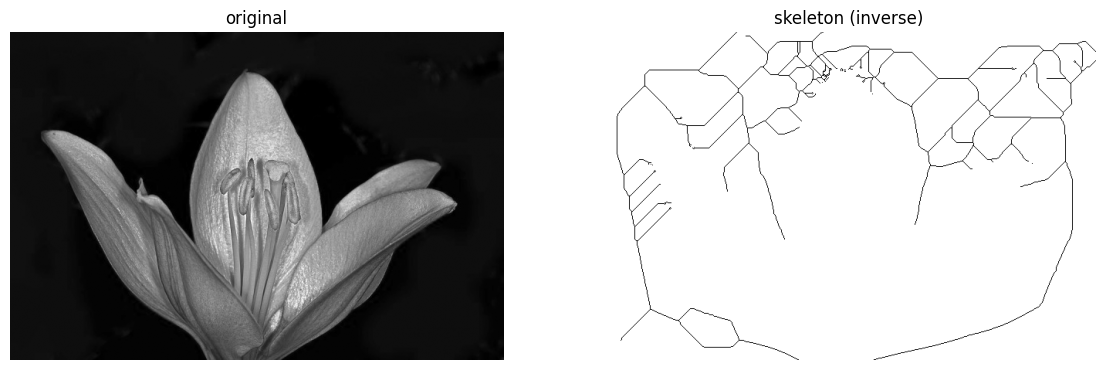

Piksel objek gelap : 175725
Piksel skeleton    : 4340


In [29]:
from skimage import io
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread(path('lily.jpg'))[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

print('Piksel objek gelap :', int(binary.sum()))
print('Piksel skeleton    :', int(skeleton.sum()))

### Pembahasan langkah 16

- Dengan operator `<`, piksel gelap menjadi objek. Skeleton yang dihasilkan mengikuti bagian gelap citra, yaitu bayangan dan kontur dalam kelopak bunga.
- Colormap `gray_r` dipakai agar nilai skeleton (True) tampil sebagai garis gelap pada latar terang, sesuai kebiasaan visual skeleton pada modul.
- Perbedaan hasil dengan langkah 15 menunjukkan bahwa skeleton sangat bergantung pada hasil segmentasi. Perubahan aturan threshold membalik objek yang dianalisis dan menghasilkan kerangka yang sama sekali berbeda.

## 17. Thickening / Thinning

Modul menjelaskan *thickening* sebagai kebalikan dari *thinning*: penebalan himpunan A oleh SE dilakukan dengan menipiskan komplemennya, `A (thick) B = A union (A^c (thin) B)`. Pada praktiknya scikit-image menyediakan `morphology.thin` untuk menipiskan objek, dan penebalan diperoleh dengan menerapkannya pada latar citra.

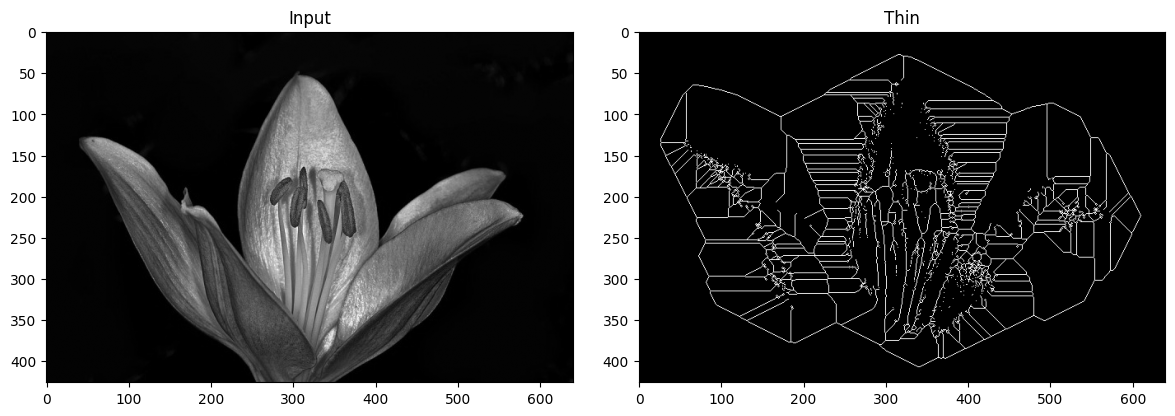

Piksel objek biner   : 246422
Piksel hasil thin    : 13017
Piksel hasil skeleton: 12993


In [30]:
from skimage import img_as_float
from skimage import io, color, morphology

image = img_as_float(color.rgb2gray(io.imread(path('lily.jpg'))))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.tight_layout()
plt.show()

print('Piksel objek biner   :', int(image_binary.sum()))
print('Piksel hasil thin    :', int(out_thin.sum()))
print('Piksel hasil skeleton:', int(out_skeletonize.sum()))

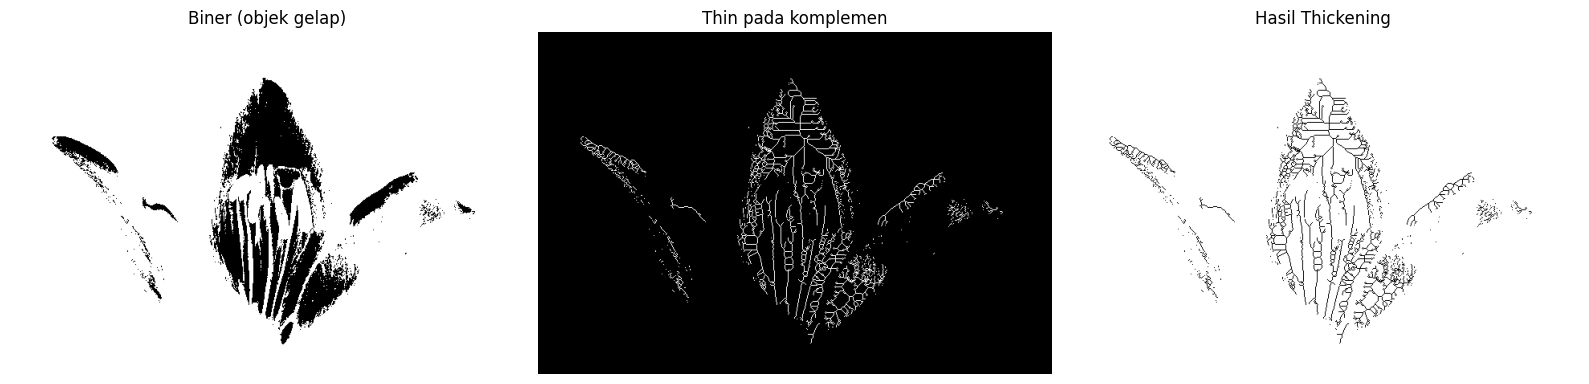

Piksel objek sebelum thickening : 246422
Piksel objek sesudah thickening : 266508


In [31]:
# Thickening: penipisan dilakukan pada komplemen citra, lalu digabung dengan citra asli
tebal = morphology.thin(~image_binary)
hasil_tebal = image_binary | ~tebal

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(image_binary, cmap='gray'), ax[0].set_title('Biner (objek gelap)'), ax[0].set_axis_off()
ax[1].imshow(tebal, cmap='gray'), ax[1].set_title('Thin pada komplemen'), ax[1].set_axis_off()
ax[2].imshow(hasil_tebal, cmap='gray'), ax[2].set_title('Hasil Thickening'), ax[2].set_axis_off()
plt.tight_layout()
plt.show()

print('Piksel objek sebelum thickening :', int(image_binary.sum()))
print('Piksel objek sesudah thickening :', int(hasil_tebal.sum()))

### Pembahasan langkah 17

- `morphology.thin` menghasilkan objek setebal satu piksel, mirip skeleton, tetapi tidak menjamin kerangka berada tepat di tengah objek. Karena itu jumlah piksel hasil *thin* umumnya sedikit berbeda dengan *skeletonize*.
- Thickening dihitung dengan menipiskan komplemen citra lalu menggabungkannya kembali dengan objek asli. Hasilnya objek bertambah tebal pada bagian yang sebelumnya tipis atau berlubang.
- Jumlah piksel objek bertambah setelah thickening, kebalikan dari erosi dan thinning yang selalu mengurangi jumlah piksel objek.

---

# E. Tugas Praktikum - Penerapan Morfologi pada Citra KTP (Dataset Modul 7)

Tugas akhir modul meminta seluruh teknik morfologi diterapkan pada citra KTP agar teks pada KTP terbaca lebih baik. Citra KTP memiliki ciri khas: latar berwarna terang dengan pola garis halus (*guilloche*), teks gelap berukuran kecil, dan elemen foto yang mengandung gradasi.

Tahapan yang dilakukan:

1. Membaca citra KTP dan mengubahnya ke grayscale.
2. Segmentasi awal dengan threshold Otsu (`THRESH_BINARY_INV`) agar teks menjadi objek putih.
3. **Opening** untuk menghapus pola garis latar yang tipis.
4. **Closing** untuk menyambung goresan huruf yang terputus.
5. **Top-hat** dan **bottom-hat** untuk menonjolkan detail kecil terang dan gelap.
6. **Skeleton** untuk memeriksa ketebalan goresan huruf.
7. Membandingkan keterbacaan citra sebelum dan sesudah rangkaian operasi.

Dimensi citra KTP : (600, 900)
Rentang intensitas: 0 - 255


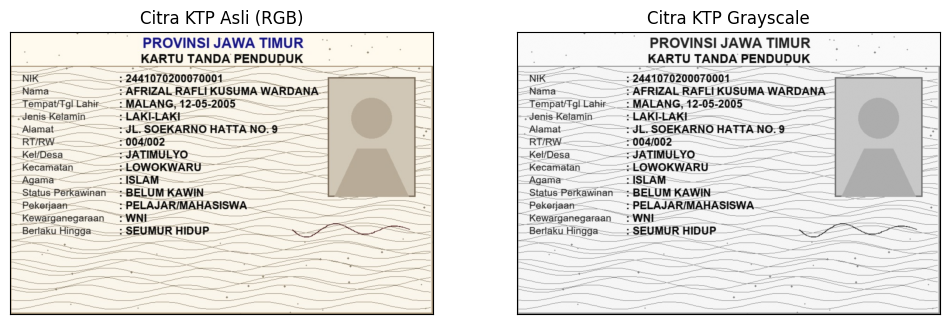

In [32]:
# 1. Membaca citra KTP dan konversi ke grayscale
ktp_bgr = cv2.imread(path('ktp.jpg'))
ktp = cv2.cvtColor(ktp_bgr, cv2.COLOR_BGR2GRAY)

print('Dimensi citra KTP :', ktp.shape)
print('Rentang intensitas:', int(ktp.min()), '-', int(ktp.max()))

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(cv2.cvtColor(ktp_bgr, cv2.COLOR_BGR2RGB))
plt.title('Citra KTP Asli (RGB)'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(ktp, cmap='gray')
plt.title('Citra KTP Grayscale'), plt.xticks([]), plt.yticks([])
plt.show()

Nilai threshold Otsu : 180.0


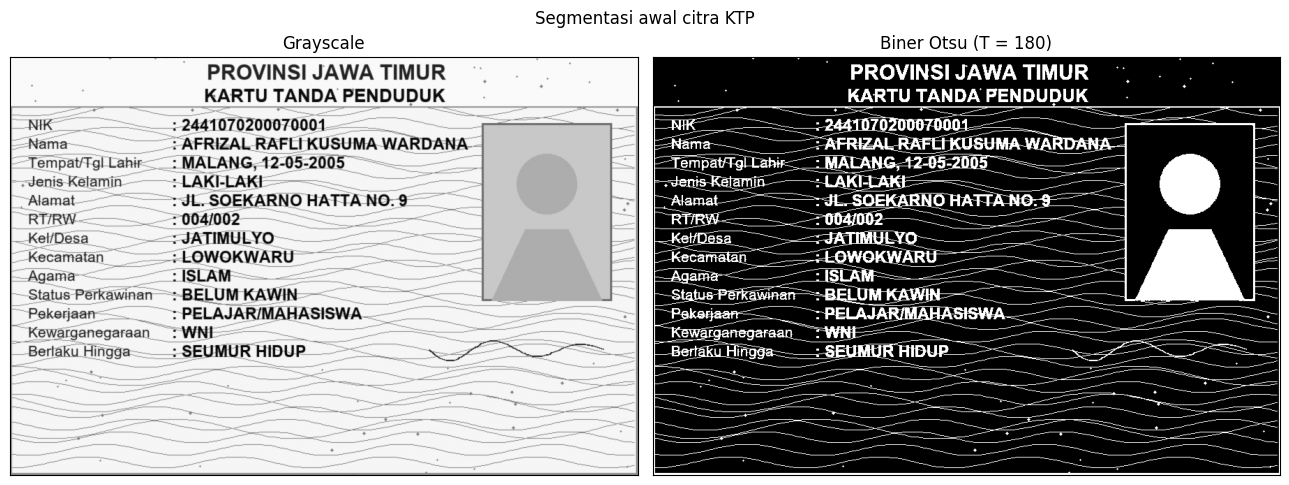

Piksel objek sebelum morfologi : 94877
Jumlah komponen terhubung      : 103


In [33]:
# 2. Segmentasi dengan threshold Otsu, dibalik agar teks menjadi objek (putih)
nilai_otsu, ktp_biner = cv2.threshold(ktp, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print('Nilai threshold Otsu :', nilai_otsu)

tampil('Segmentasi awal citra KTP',
       [ktp, ktp_biner],
       ['Grayscale', f'Biner Otsu (T = {nilai_otsu:.0f})'],
       figsize=(13, 5))

print('Piksel objek sebelum morfologi :', statistik_biner(ktp_biner)[0])
print('Jumlah komponen terhubung      :', statistik_biner(ktp_biner)[2])

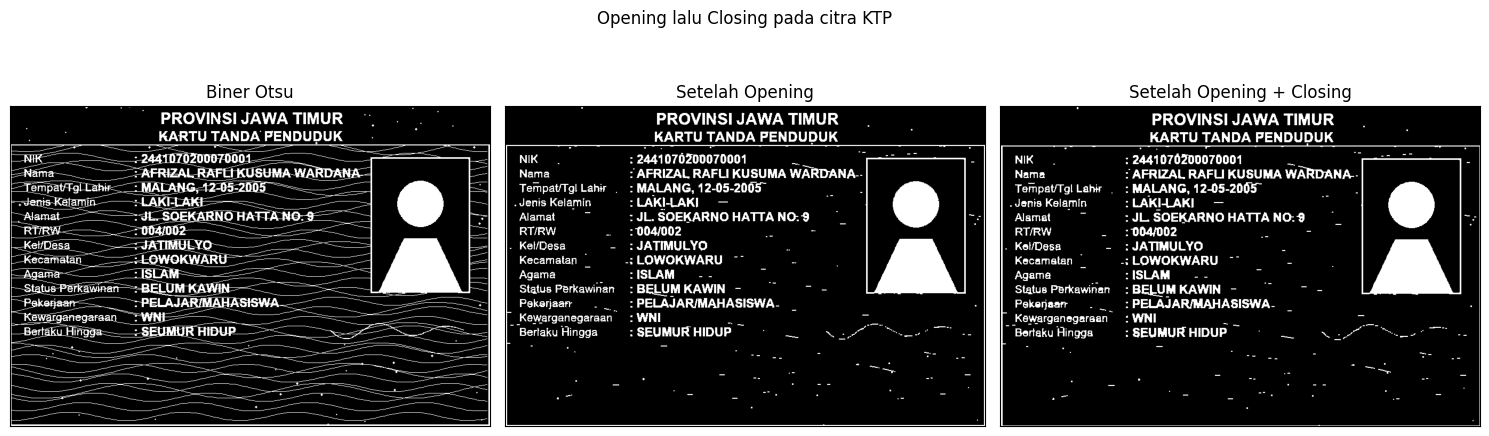

Biner Otsu       piksel=  94877 (17.57%)  komponen=103
Opening          piksel=  66016 (12.23%)  komponen=505
Opening+Closing  piksel=  65867 (12.20%)  komponen=435


In [34]:
# 3. Opening: menghapus pola garis latar yang tipis dan bintik noise
kernel_open = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
ktp_open = cv2.morphologyEx(ktp_biner, cv2.MORPH_OPEN, kernel_open)

# 4. Closing: menyambung goresan huruf yang terputus
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
ktp_close = cv2.morphologyEx(ktp_open, cv2.MORPH_CLOSE, kernel_close)

tampil('Opening lalu Closing pada citra KTP',
       [ktp_biner, ktp_open, ktp_close],
       ['Biner Otsu', 'Setelah Opening', 'Setelah Opening + Closing'],
       figsize=(15, 5))

for nama, citra in [('Biner Otsu', ktp_biner), ('Opening', ktp_open), ('Opening+Closing', ktp_close)]:
    putih, persen, komponen = statistik_biner(citra)
    print(f'{nama:<16} piksel={putih:>7} ({persen:5.2f}%)  komponen={komponen}')

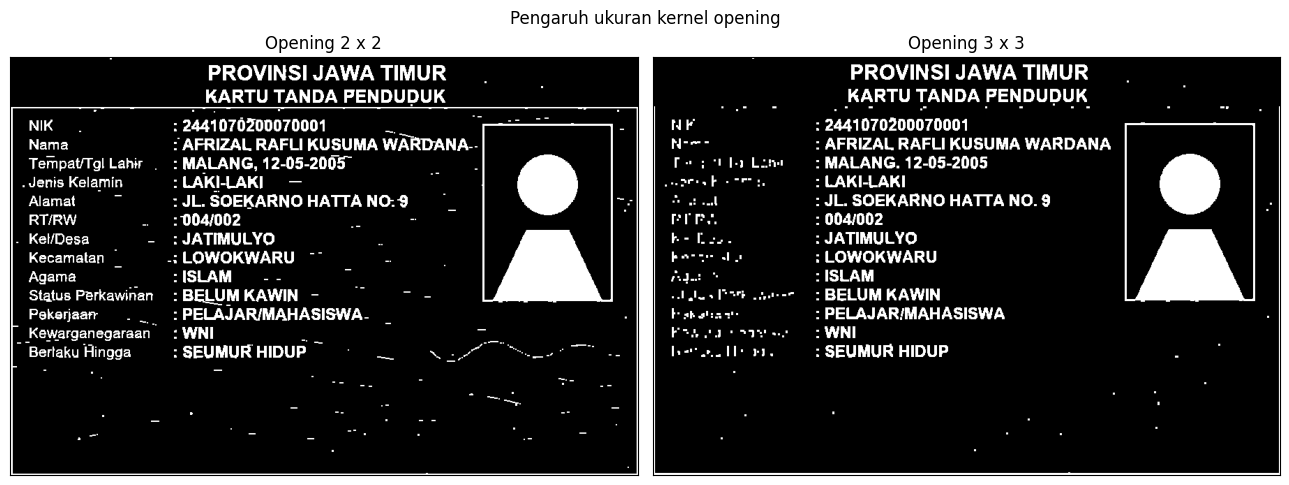

Opening 2x2  piksel=  66016 (12.23%)  komponen=505
Opening 3x3  piksel=  58162 (10.77%)  komponen=432


In [35]:
# Perbandingan ukuran kernel opening: 2 x 2 cukup untuk menghapus garis 1 piksel,
# kernel 3 x 3 mulai menggerus goresan huruf yang tipis
ktp_open3 = cv2.morphologyEx(ktp_biner, cv2.MORPH_OPEN,
                             cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)))

tampil('Pengaruh ukuran kernel opening',
       [ktp_open, ktp_open3],
       ['Opening 2 x 2', 'Opening 3 x 3'],
       figsize=(13, 5))

for nama, citra in [('Opening 2x2', ktp_open), ('Opening 3x3', ktp_open3)]:
    putih, persen, komponen = statistik_biner(citra)
    print(f'{nama:<12} piksel={putih:>7} ({persen:5.2f}%)  komponen={komponen}')

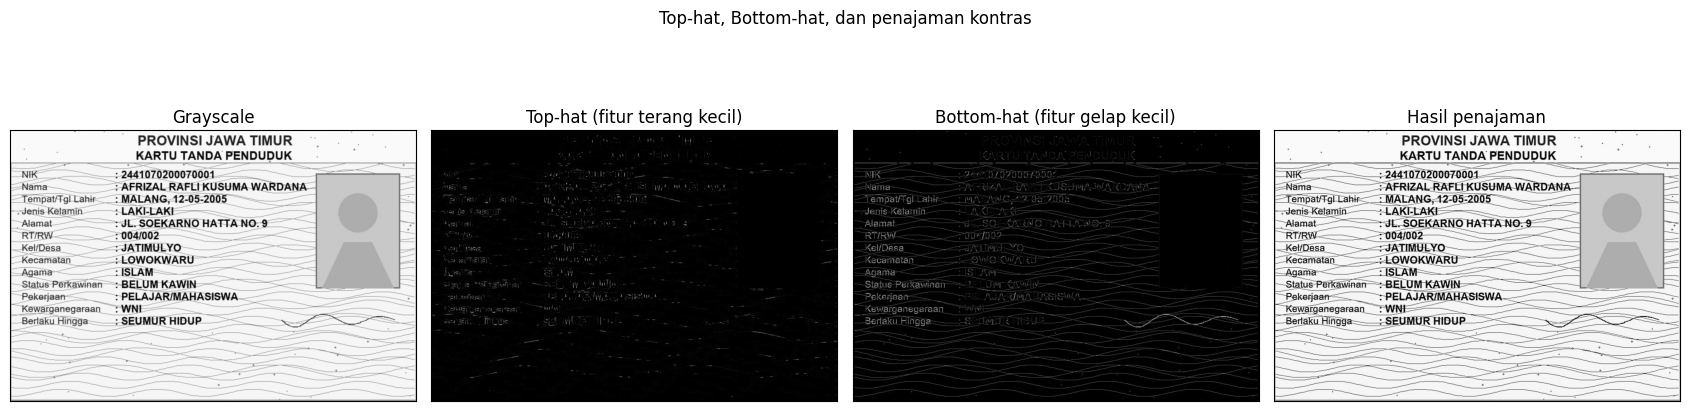

In [36]:
# 5. Top-hat dan Bottom-hat pada citra grayscale KTP
kernel_th = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
ktp_tophat = cv2.morphologyEx(ktp, cv2.MORPH_TOPHAT, kernel_th)
ktp_blackhat = cv2.morphologyEx(ktp, cv2.MORPH_BLACKHAT, kernel_th)

# Penajaman kontras memakai top-hat dan bottom-hat
ktp_enhance = cv2.add(ktp, ktp_tophat)
ktp_enhance = cv2.subtract(ktp_enhance, ktp_blackhat)

tampil('Top-hat, Bottom-hat, dan penajaman kontras',
       [ktp, ktp_tophat, ktp_blackhat, ktp_enhance],
       ['Grayscale', 'Top-hat (fitur terang kecil)', 'Bottom-hat (fitur gelap kecil)', 'Hasil penajaman'],
       figsize=(17, 5))

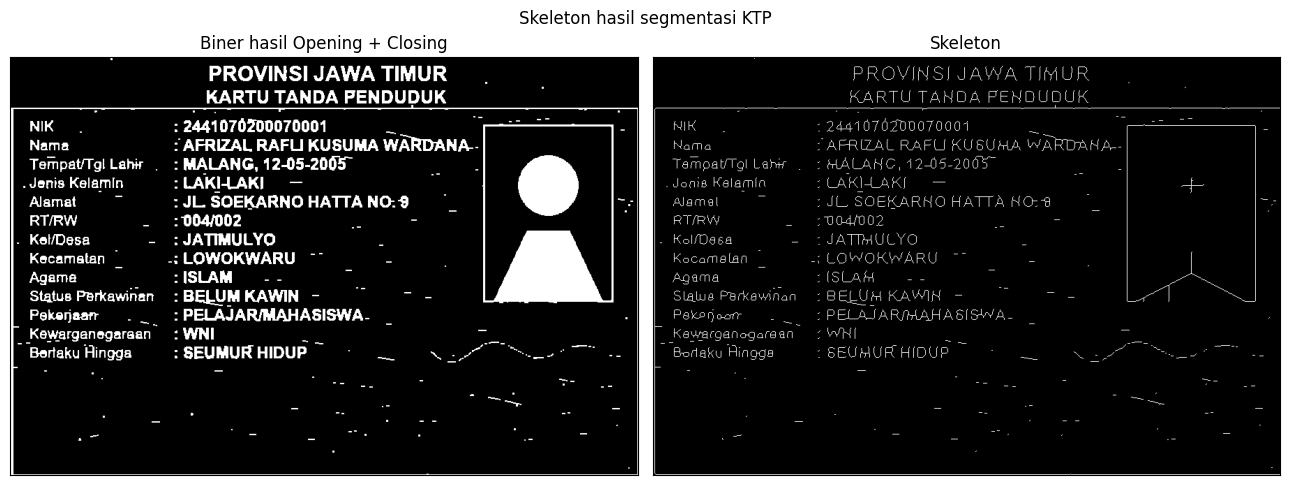

Piksel objek biner : 65867
Piksel skeleton    : 14712


In [37]:
# 6. Skeleton pada hasil segmentasi, untuk memeriksa ketebalan goresan huruf
from skimage.morphology import skeletonize

ktp_skel = skeletonize(ktp_close > 0)
ktp_skel_img = (ktp_skel * 255).astype(np.uint8)

tampil('Skeleton hasil segmentasi KTP',
       [ktp_close, ktp_skel_img],
       ['Biner hasil Opening + Closing', 'Skeleton'],
       figsize=(13, 5))

print('Piksel objek biner :', statistik_biner(ktp_close)[0])
print('Piksel skeleton    :', int(ktp_skel.sum()))

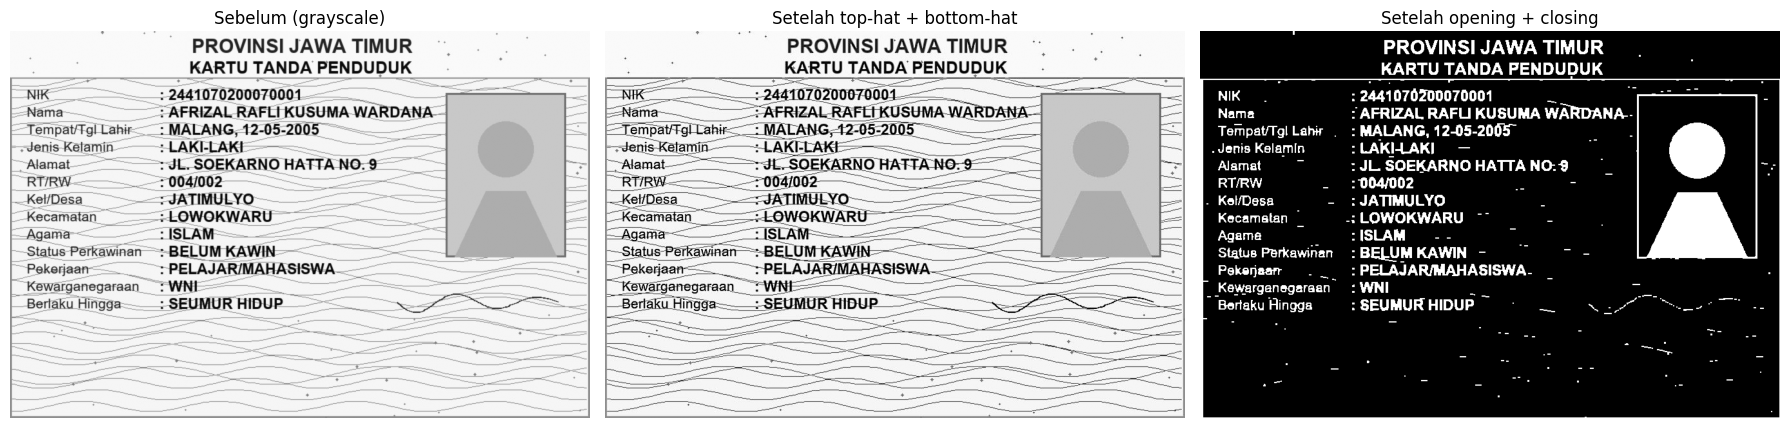

Grayscale    std intensitas =   53.46   varians Laplacian =    4097.37
Penajaman    std intensitas =   65.30   varians Laplacian =   13564.26
Biner akhir  std intensitas =   83.45   varians Laplacian =   11059.58


In [38]:
# 7. Perbandingan keterbacaan sebelum dan sesudah rangkaian morfologi
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(ktp, cmap='gray'), ax[0].set_title('Sebelum (grayscale)'), ax[0].set_axis_off()
ax[1].imshow(ktp_enhance, cmap='gray'), ax[1].set_title('Setelah top-hat + bottom-hat'), ax[1].set_axis_off()
ax[2].imshow(ktp_close, cmap='gray'), ax[2].set_title('Setelah opening + closing'), ax[2].set_axis_off()
plt.tight_layout()
plt.show()

# Metrik sederhana: kontras (standar deviasi) dan ketajaman (varians Laplacian)
def skor_keterbacaan(citra):
    lap = cv2.Laplacian(citra, cv2.CV_64F)
    return float(citra.std()), float(lap.var())

for nama, citra in [('Grayscale', ktp), ('Penajaman', ktp_enhance), ('Biner akhir', ktp_close)]:
    std, ketajaman = skor_keterbacaan(citra)
    print(f'{nama:<12} std intensitas = {std:7.2f}   varians Laplacian = {ketajaman:10.2f}')

### Analisis Tugas Praktikum

1. **Segmentasi.** Threshold Otsu memisahkan teks dari latar KTP secara otomatis tanpa ambang manual. Karena latar KTP lebih terang daripada teks, operator `THRESH_BINARY_INV` dipakai agar teks menjadi objek putih yang dapat diproses morfologi. Hasil segmentasi masih membawa pola garis *guilloche* dan bintik, sehingga jumlah piksel objek jauh lebih besar daripada luas teks sebenarnya.

2. **Peran opening.** Opening dengan SE persegi 2 x 2 menghapus garis *guilloche* setebal satu piksel, karena erosi 2 x 2 tidak mungkin mempertahankan objek setipis itu. Persentase piksel objek turun dari 17,57% menjadi 12,23% (lihat keluaran). Jumlah komponen terhubung justru **naik** dari 103 menjadi 505: jaringan garis yang sebelumnya saling menyambung terpotong menjadi pecahan-pecahan kecil, dan pecahan itulah yang terhitung sebagai komponen baru. Teks utama tetap utuh karena goresannya lebih tebal dari SE.

3. **Peran closing.** Closing 2 x 2 mengisi celah kecil pada goresan huruf yang terputus akibat threshold. Jumlah komponen turun dari 505 menjadi 435, yang berarti potongan huruf dan sisa garis yang berdekatan menyatu kembali, dan huruf tampak lebih padat tanpa bertambah tebal berlebihan.

4. **Pengaruh ukuran kernel.** Opening 3 x 3 menghapus lebih banyak garis latar, tetapi mulai menggerus goresan huruf yang tipis: persentase piksel objek turun lebih jauh dibanding opening 2 x 2. Karena itu kernel 2 x 2 dipilih sebagai titik seimbang antara kebersihan latar dan keutuhan huruf.

5. **Peran top-hat dan bottom-hat.** Top-hat menyisakan detail terang kecil, bottom-hat menyisakan detail gelap kecil. Kombinasi `citra + top-hat - bottom-hat` menaikkan kontras lokal sehingga tepi huruf lebih tegas dibanding citra grayscale asli. Nilai standar deviasi intensitas dan varians Laplacian meningkat, yang menandakan sebaran nilai piksel makin lebar (kontras naik) dan tepi makin tajam.

6. **Peran skeleton.** Skeleton menunjukkan bahwa goresan huruf pada KTP hanya setebal beberapa piksel. Skeleton mempertahankan topologi huruf sehingga bentuk karakter tetap dapat dikenali meski sebagian besar piksel dihilangkan. Rasio piksel skeleton terhadap piksel objek pada citra ini dapat dilihat pada keluaran, dan nilainya kecil karena objek aslinya jauh lebih tebal daripada kerangkanya.

7. **Kesimpulan tugas.** Rangkaian *threshold Otsu -> opening 2 x 2 -> closing 2 x 2* adalah kombinasi yang paling efektif untuk memperbaiki keterbacaan KTP pada praktikum ini. Opening membersihkan pola latar, closing memperbaiki objek, top-hat dan bottom-hat menaikkan kontras, dan hasil akhirnya lebih siap untuk tahap pengenalan karakter (OCR) dibanding citra asli.

---

## Kesimpulan

1. **Structuring element adalah inti morfologi.** Bentuk dan ukuran SE menentukan arah perubahan objek. SE persegi menebal atau menipis ke segala arah, SE *cross* hanya ke arah vertikal dan horizontal, SE lingkaran memberi perubahan membulat, dan SE garis vertikal hanya mempertahankan struktur vertikal.

2. **Erosi dan dilasi adalah pasangan.** Erosi mengurangi jumlah piksel objek dan menghilangkan detail yang lebih kecil dari SE. Dilasi menambah jumlah piksel objek dan menutup lubang kecil. Keduanya bersifat dual: dilasi pada objek setara dengan erosi pada latar.

3. **Opening dan closing adalah operasi turunan yang lebih terkontrol.** Opening (erosi lalu dilasi) menghapus noise eksternal tanpa mengubah ukuran objek utama. Closing (dilasi lalu erosi) menutup lubang internal dan menyambung objek yang retak. Keduanya idempotent, sehingga aman diulang.

4. **Top-hat dan bottom-hat mengekstrak detail kecil.** Top-hat (`f - opening`) menyisakan fitur terang kecil, bottom-hat (`closing - f`) menyisakan fitur gelap kecil. Keduanya berguna sebagai praproses sebelum threshold pada citra dengan pencahayaan tidak merata.

5. **Skeleton dan thickening melengkapi analisis bentuk.** Skeleton meringkas objek menjadi kerangka satu piksel dengan topologi tetap, berguna untuk mengukur panjang dan intensitas rekahan. Thickening, sebagai kebalikan thinning, menebalkan objek dengan menipiskan komplemennya.

6. **Implementasi manual dan library menghasilkan keluaran yang setara.** Selisih hanya terjadi di tepi citra karena penanganan *border* yang berbeda, sedangkan versi library jauh lebih cepat. Pemahaman implementasi manual tetap penting agar perilaku setiap operator dapat dijelaskan, bukan hanya dipakai.

7. **Penerapan pada KTP.** Kombinasi threshold Otsu, opening, dan closing berhasil membersihkan pola latar dan menyambung goresan huruf KTP. Top-hat dan bottom-hat menaikkan kontras lokal, sedangkan skeleton memastikan struktur huruf tetap terjaga.